step 1 : Understand the Goal
fetch 1 year NIFTY historical data
clean the data
perform EDA
#Create features
Train ML model
predict tomorrow's Nifty close price

step 2 : Fetch NIFTY Data from Yahoo Finance

In [1]:
import yfinance as yf
import pandas as pd
import matplotlib.pyplot as plt 

In [2]:
df = yf.download("^NSEI",period="5y")
df.to_excel("nifty_data.xlsx")

[*********************100%***********************]  1 of 1 completed


Column Description
Date - Trading date
Open - Price when market opend
High - Highest price reached that day
Low - Lowest price reached that day
Close - Final price when market closed
Volume - Total buying/selling activityy

In [7]:
df.shape

(1236, 5)

In [8]:
df.info()

<class 'pandas.DataFrame'>
DatetimeIndex: 1236 entries, 2021-05-14 to 2026-05-14
Data columns (total 5 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   (Close, ^NSEI)   1236 non-null   float64
 1   (High, ^NSEI)    1236 non-null   float64
 2   (Low, ^NSEI)     1236 non-null   float64
 3   (Open, ^NSEI)    1236 non-null   float64
 4   (Volume, ^NSEI)  1236 non-null   int64  
dtypes: float64(4), int64(1)
memory usage: 57.9 KB


No missing value 
all are numeric cols

In [9]:
df.describe()

Price,Close,High,Low,Open,Volume
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI
count,1236.000000,1236.000000,1236.000000,1236.000000,1.236000e+03
mean,20757.165352,20856.493310,20651.645189,20764.886005,3.061536e+05
std,3445.777275,3457.564983,3438.070797,3446.308014,1.046865e+05
min,14677.799805,14749.650391,14591.900391,14749.400391,0.000000e+00
25%,17617.900391,17706.624512,17510.975098,17631.887695,2.412500e+05
50%,19811.424805,19867.350586,19757.674805,19825.574219,2.824500e+05
75%,24289.250000,24369.162598,24142.763184,24302.774902,3.544500e+05
max,26328.550781,26373.199219,26210.050781,26333.699219,1.006100e+06


avg Close point - 20757
avg High point - 20856
avg Low - 20651
avg Open - 20764
avg vol  - 3.061536e+05

Highest NIFTY close max = 26328

Min Volumn is = 00000 sus


In [16]:
df.columns = df.columns.get_level_values(0)
df[df['Volume'] == 0]

Price,Close,High,Low,Open,Volume
Date,,,,,
2021-05-27,15337.849609,15384.549805,15272.500000,15323.950195,0
2021-07-14,15853.950195,15877.349609,15764.200195,15808.700195,0
2022-08-16,17825.250000,17839.099609,17764.050781,17797.199219,0
2023-03-22,17151.900391,17207.250000,17107.849609,17177.449219,0
2023-08-16,19465.000000,19482.750000,19317.199219,19369.000000,0
2024-02-19,22122.250000,22186.650391,22021.050781,22103.449219,0
2024-04-01,22462.000000,22529.949219,22427.750000,22455.000000,0
2024-07-01,24141.949219,24164.000000,23992.699219,23992.949219,0
2024-07-02,24123.849609,24236.349609,24056.400391,24228.750000,0


In [17]:
df['Volume'].value_counts()

Volume
0         11
261400     5
230200     5
295700     4
254800     3
          ..
440600     1
335900     1
390100     1
447500     1
415400     1
Name: count, Length: 1010, dtype: int64

In [18]:
import numpy as np

In [19]:
df['Volume'] = df['Volume'].replace(0,np.nan)

In [20]:
df.corr()

Price,Close,High,Low,Open,Volume
Price,,,,,
Close,1.000000,0.999608,0.999650,0.999153,0.152959
High,0.999608,1.000000,0.999481,0.999699,0.159895
Low,0.999650,0.999481,1.000000,0.999506,0.146027
Open,0.999153,0.999699,0.999506,1.000000,0.154877
Volume,0.152959,0.159895,0.146027,0.154877,1.000000


Correlation scale
0.0 -> no relation
0.1 - 0.3 -> weak relation
0.3-0.7-> moderate
0.7 -> strong
so volume has weak relationship 

In [26]:
df.duplicated().sum()

np.int64(0)

No duplicate Entry

Univariate Analysis

In [4]:
df['Close'].describe()

Ticker,^NSEI
count,1236.000000
mean,20757.211307
std,3445.816839
min,14677.799805
25%,17617.900391
50%,19811.424805
75%,24289.250000
max,26328.550781


<Axes: ylabel='Frequency'>

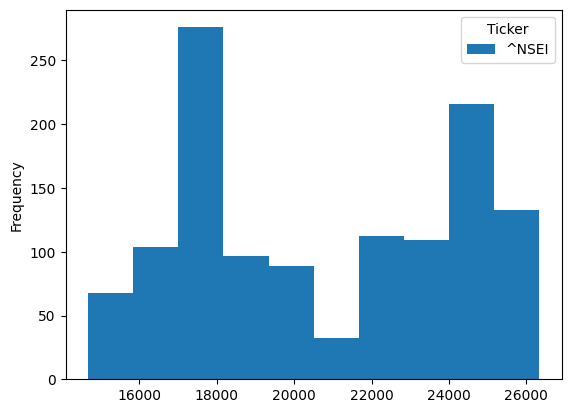

In [5]:
df['Close'].plot(kind='hist')

<Axes: ylabel='Density'>

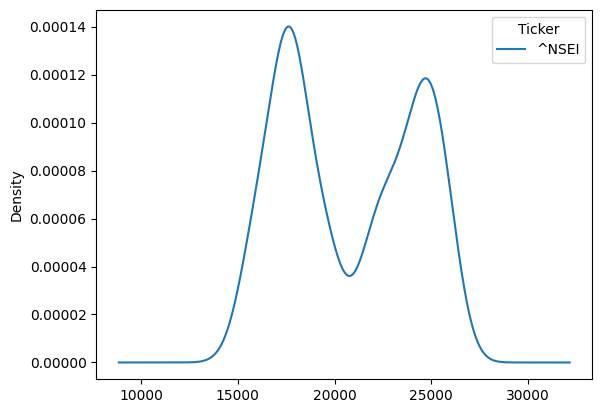

In [6]:
df['Close'].plot(kind='kde')

In [7]:
df['Close'].skew()

Ticker
^NSEI    0.079228
dtype: float64

<Axes: >

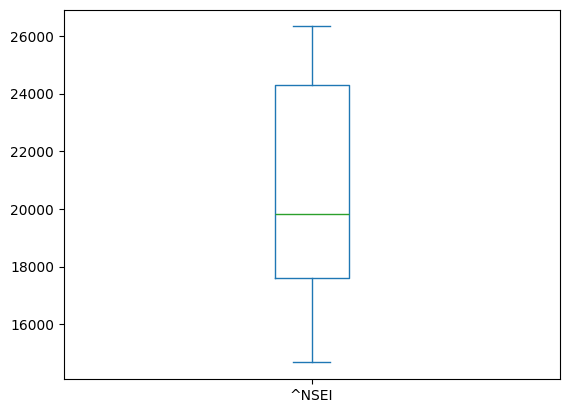

In [8]:
df['Close'].plot(kind='box')

No oulier in Close

<Axes: ylabel='Frequency'>

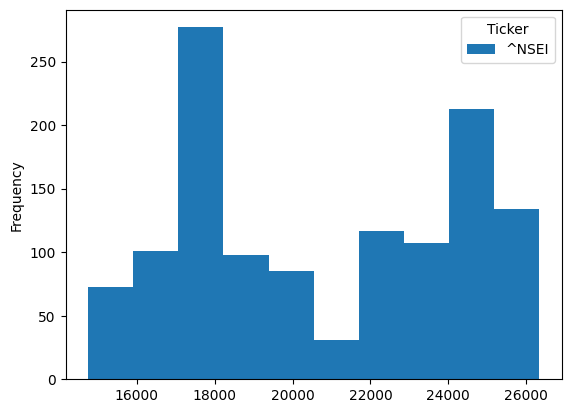

In [9]:
df['Open'].plot(kind='hist')

<Axes: ylabel='Density'>

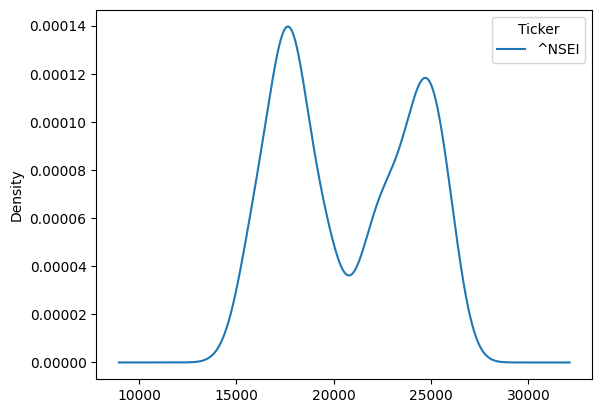

In [10]:
df['Open'].plot(kind='kde')

In [11]:
df['Open'].skew()

Ticker
^NSEI    0.079296
dtype: float64

<Axes: >

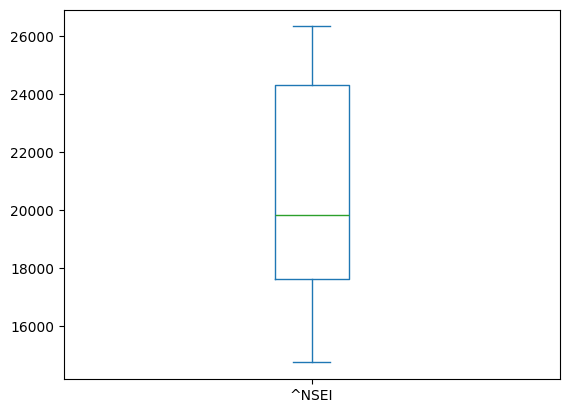

In [12]:
df['Open'].plot(kind='box')

<Axes: >

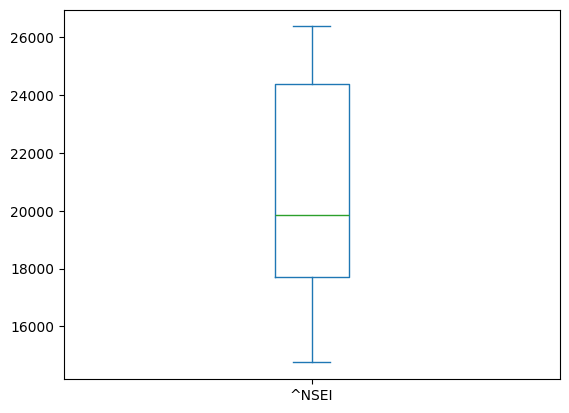

In [13]:
df['High'].plot(kind='box')

<Axes: ylabel='Density'>

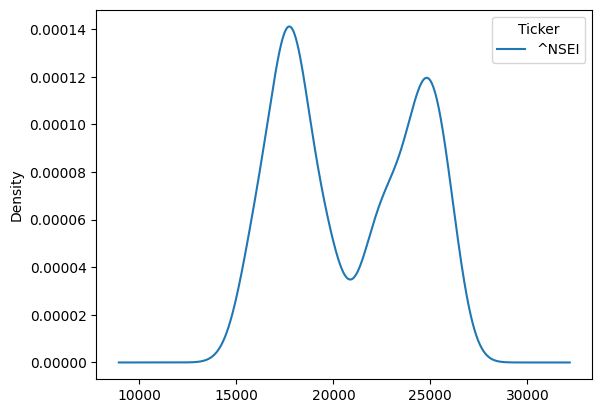

In [15]:
df['High'].plot(kind='kde')

<Axes: ylabel='Density'>

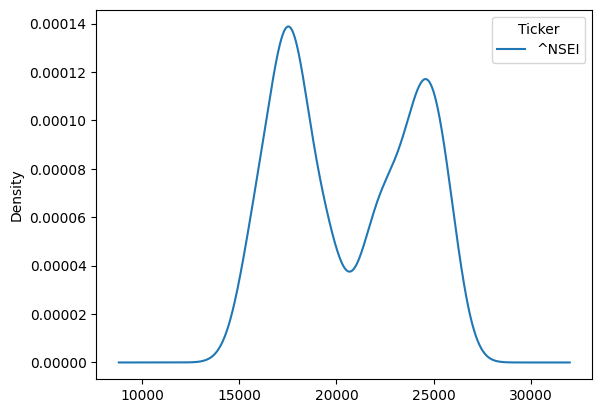

In [16]:
df['Low'].plot(kind='kde')

<Axes: ylabel='Density'>

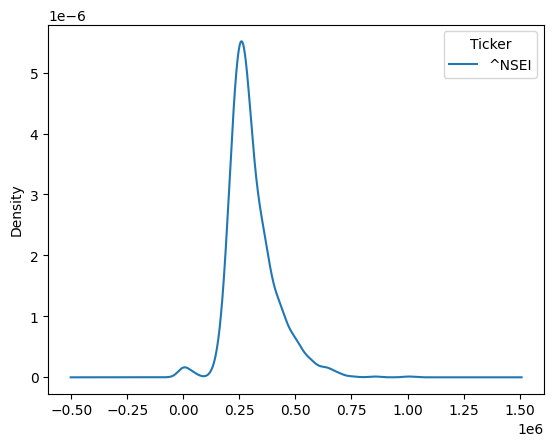

In [17]:
df['Volume'].plot(kind='kde')

In [18]:
df['Volume'].skew()

Ticker
^NSEI    1.152343
dtype: float64

Right skewed

<Axes: >

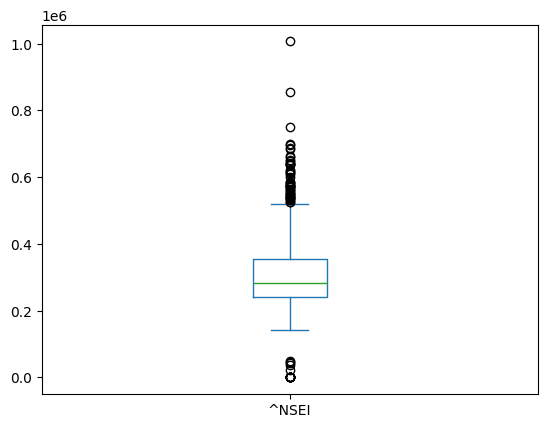

In [29]:
df['Volume'].plot(kind='box')

In [30]:
Q1 = df['Volume'].quantile(0.25)
Q3 = df['Volume'].quantile(0.75)
IQR = Q3 - Q1
lower = Q1 - 1.5 *IQR
upper = Q3 + 1.5 * IQR
print(lower)
print(upper)
outliers = df[(df['Volume'] < lower) | (df['Volume'] > upper)]
print(outliers)

Ticker
^NSEI    71450.0
dtype: float64
Ticker
^NSEI    524250.0
dtype: float64
Price              Close          High           Low          Open    Volume
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI     ^NSEI
Date                                                                        
2021-05-14  14677.799805  14749.650391  14591.900391  14749.400391  620700.0
2021-05-17  14923.150391  14938.000000  14725.349609  14756.250000  546400.0
2021-05-18  15108.099609  15137.250000  15043.700195  15067.200195  583900.0
2021-05-19  15030.150391  15133.400391  15008.849609  15058.599609  569100.0
2021-05-20           NaN           NaN           NaN           NaN       NaN
...                  ...           ...           ...           ...       ...
2026-05-08           NaN           NaN           NaN           NaN       NaN
2026-05-11           NaN           NaN           NaN           NaN       NaN
2026-05-12           NaN           NaN           NaN           NaN       N

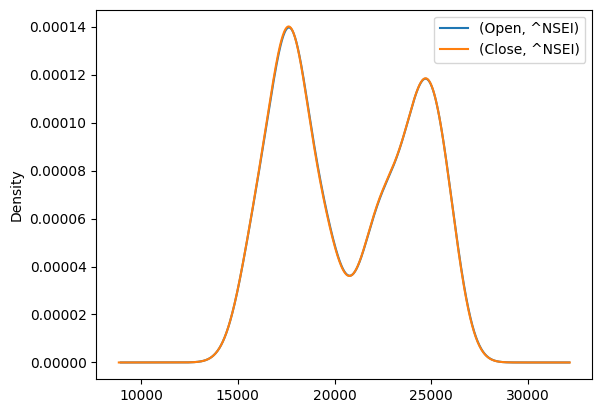

In [35]:
df[['Open', 'Close']].plot(kind='kde')
plt.legend()
plt.show()

In [43]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

X = df[['Open', 'High', 'Low', 'Volume']]
y = df['Close']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)#shuffle=False

model = LinearRegression()
model.fit(X_train, y_train)

y_pred = model.predict(X_test)

print("MAE:", mean_absolute_error(y_test, y_pred))
print("MSE:", mean_squared_error(y_test, y_pred))
print("R2 Score:", r2_score(y_test, y_pred))



MAE: 38.534570733919
MSE: 2727.3465872384654
R2 Score: 0.9997643484121883


In [3]:
df['Target'] = df['Close'].shift(-1)

In [4]:
df

Price,Close,High,Low,Open,Volume,Target
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI,
Date,,,,,,
2021-05-14,14677.799805,14749.650391,14591.900391,14749.400391,620700,14923.150391
2021-05-17,14923.150391,14938.000000,14725.349609,14756.250000,546400,15108.099609
2021-05-18,15108.099609,15137.250000,15043.700195,15067.200195,583900,15030.150391
2021-05-19,15030.150391,15133.400391,15008.849609,15058.599609,569100,14906.049805
2021-05-20,14906.049805,15069.799805,14884.900391,15042.599609,480300,15175.299805
...,...,...,...,...,...,...
2026-05-08,24176.150391,24253.800781,24126.650391,24233.650391,335900,23815.849609
2026-05-11,23815.849609,23997.449219,23799.099609,23970.099609,390100,23379.550781


In [5]:
df['MA5'] = df['Close'].rolling(5).mean()

In [7]:
df.describe()

Price,Close,High,Low,Open,Volume,Target,MA5
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI,,
count,1236.000000,1236.000000,1236.000000,1236.000000,1.236000e+03,1235.000000,1232.000000
mean,20757.162642,20856.545251,20651.645189,20764.886005,3.061536e+05,20762.085203,20762.169964
std,3445.774966,3457.608412,3438.070797,3446.308014,1.046865e+05,3442.820418,3437.687327
min,14677.799805,14749.650391,14591.900391,14749.400391,0.000000e+00,14906.049805,14929.050000
25%,17617.900391,17706.624512,17510.975098,17631.887695,2.412500e+05,17618.450195,17627.022559
50%,19811.424805,19867.350586,19757.674805,19825.574219,2.824500e+05,19811.500000,19799.690039
75%,24289.250000,24369.162598,24142.763184,24302.774902,3.544500e+05,24292.000000,24258.341992
max,26328.550781,26373.199219,26210.050781,26333.699219,1.006100e+06,26328.550781,26208.970313


In [9]:
df.head(10)

Price,Close,High,Low,Open,Volume,Target,MA5
Ticker,^NSEI,^NSEI,^NSEI,^NSEI,^NSEI,,
Date,,,,,,,
2021-05-14,14677.799805,14749.650391,14591.900391,14749.400391,620700,14923.150391,NaN
2021-05-17,14923.150391,14938.000000,14725.349609,14756.250000,546400,15108.099609,NaN
2021-05-18,15108.099609,15137.250000,15043.700195,15067.200195,583900,15030.150391,NaN
2021-05-19,15030.150391,15133.400391,15008.849609,15058.599609,569100,14906.049805,NaN
2021-05-20,14906.049805,15069.799805,14884.900391,15042.599609,480300,15175.299805,14929.050000
2021-05-21,15175.299805,15190.000000,14985.849609,14987.799805,572900,15197.700195,15028.550000
2021-05-24,15197.700195,15256.250000,15145.450195,15211.349609,579800,15208.450195,15083.459961
2021-05-25,15208.450195,15293.849609,15163.400391,15291.750000,441500,15301.450195,15103.530078
